## Ćwiczenie 11. Zadania

W tym zeszycie sprawdzisz swoje umiejętności budowy potoków rejestracji obrazów z wykorzystaniem biblioteki **SimpleITK**. 
Twoim zadaniem jest nałożenie na siebie obróconych i przesuniętych skanów w dwóch scenariuszach:
1. **Rejestracja Jednomodalna (CT -> CT):** Dopasowanie dwóch obrazów o tej samej charakterystyce jasności.
2. **Rejestracja Wielomodalna (CT -> MRI):** Dopasowanie obrazów o odwróconym kontraście (np. jasne kości w CT, ciemne w MRI).

W miejscach oznaczonych jako `TODO` uzupełnij brakujący kod na podstawie wiedzy z zajęć.

In [2]:
# Instalacja i import niezbędnych pakietów
#!pip install SimpleITK

import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Funkcja pomocnicza do wyświetlania mapy różnic
def plot_difference(fixed, moving, registered, title_prefix=""):
    diff_before = sitk.GetArrayFromImage(fixed) - sitk.GetArrayFromImage(moving)
    diff_after = sitk.GetArrayFromImage(fixed) - sitk.GetArrayFromImage(registered)
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(diff_before, cmap='bwr', vmin=-1, vmax=1)
    ax[0].set_title(f'{title_prefix} Różnica PRZED (idealnie = płaski kolor)')
    ax[1].imshow(diff_after, cmap='bwr', vmin=-1, vmax=1)
    ax[1].set_title(f'{title_prefix} Różnica PO rejestracji')
    plt.show()

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


## ZADANIE 1: Rejestracja Jednomodalna (TK vs TK)
Najpierw wczytamy obraz Tomografii Komputerowej (TK/CT). Możesz podać ścieżkę do własnego pliku lub skorzystać z wbudowanego przykładu.

Ładowanie przykładowego obrazu CT...


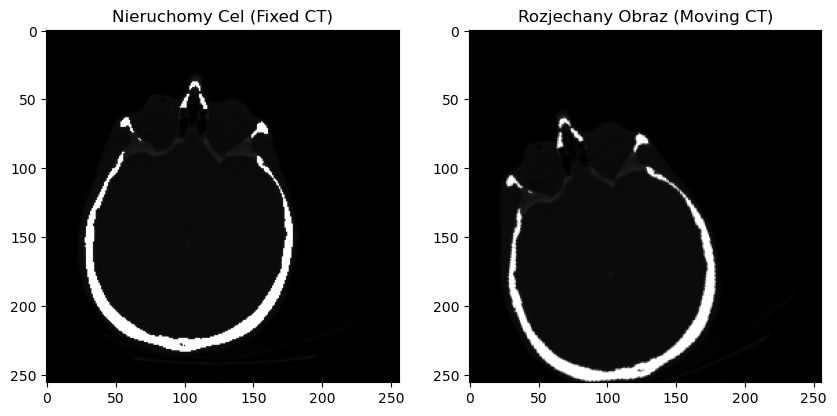

In [5]:
# TODO: (Opcjonalnie) Podaj ścieżkę do własnego pliku z obrazem TK.
# Użyj funkcji sitk.ReadImage(sciezka, sitk.sitkFloat32)
# Jeśli nie masz pliku, kod poniżej załaduje przykładowy przekrój.

try:
    # Zmień na własny plik, np.: fixed_ct = sitk.ReadImage("moj_skan.nii.gz", sitk.sitkFloat32)
    fixed_ct = None 
    if fixed_ct is None:
        raise ValueError("Brak pliku")
except:
    print("Ładowanie przykładowego obrazu CT...")
    brain_np = data.brain()[5, :, :].astype(np.float32)
    brain_np = (brain_np - brain_np.min()) / (brain_np.max() - brain_np.min())
    
    # Wzmocnienie kontrastu kości, aby symulować prawdziwe CT
    brain_np[brain_np > 0.45] = 1.0
    brain_np[brain_np <= 0.45] *= 0.3
    
    fixed_ct = sitk.GetImageFromArray(brain_np)
    fixed_ct.SetSpacing((1.0, 1.0))
    fixed_ct.SetOrigin((0.0, 0.0))

# Celowe zepsucie obrazu docelowego (Monomodalne - TK)
transform_true_ct = sitk.Euler2DTransform()
center_pt = fixed_ct.TransformContinuousIndexToPhysicalPoint(np.array(fixed_ct.GetSize()) / 2.0)
transform_true_ct.SetCenter(center_pt)
transform_true_ct.SetTranslation((15.0, -10.0))
transform_true_ct.SetAngle(np.radians(20))

moving_ct = sitk.Resample(fixed_ct, fixed_ct, transform_true_ct, sitk.sitkLinear, 0.0, fixed_ct.GetPixelID())

fig, ax = plt.subplots(1, 2, figsize=(10,5))
ax[0].imshow(sitk.GetArrayFromImage(fixed_ct), cmap='gray'); ax[0].set_title("Nieruchomy Cel (Fixed CT)")
ax[1].imshow(sitk.GetArrayFromImage(moving_ct), cmap='gray'); ax[1].set_title("Rozjechany Obraz (Moving CT)")
plt.show()

In [ ]:
# ---------------------------------------------------------
# MIEJSCE NA TWÓJ KOD (Zadanie 1 - Potok Rejestracji TK)
# ---------------------------------------------------------
R_ct = sitk.ImageRegistrationMethod()

# TODO 1: Wybierz odpowiednią metrykę dla obrazów z tego samego urządzenia (np. Mean Squares)
# ...

# TODO 2: Ustaw optymalizator (np. RegularStepGradientDescent) - dobierz learningRate (np. 1.0) i liczbę iteracji
# ...

# TODO 3: Ustaw interpolator na sitkLinear
# ...

# TODO 4: Zainicjalizuj transformację z flagą MOMENTS (aby nałożyć na siebie geometryczne środki tkanek)
# init_transform_ct = ...
# R_ct.SetInitialTransform(init_transform_ct, inPlace=False)

# TODO 5: Uruchom rejestrację i zapisz ostateczną macierz w zmiennej final_transform_ct
# final_transform_ct = ...

# Poniższy kod przetestuje Twój wynik:
try:
    registered_ct = sitk.Resample(moving_ct, fixed_ct, final_transform_ct, sitk.sitkLinear, 0.0, moving_ct.GetPixelID())
    plot_difference(fixed_ct, moving_ct, registered_ct, "ZADANIE 1:")
except NameError:
    print("Zmienna final_transform_ct nie została zdefiniowana!")

## ZADANIE 2: Rejestracja Wielomodalna (TK vs sztuczne MRI)
Syntetyczny obraz Rezonansu Magnetycznego (MRI) zostanie wygenerowany z TK. 
Odwrócimy kontrast: to, co w TK było jasne (kości), w MRI będzie czarne.

Zwykły błąd średniokwadratowy tutaj całkowicie zawiedzie! Twoim zadaniem będzie użycie algorytmu wielorozdzielczego i zaawansowanych metryk.

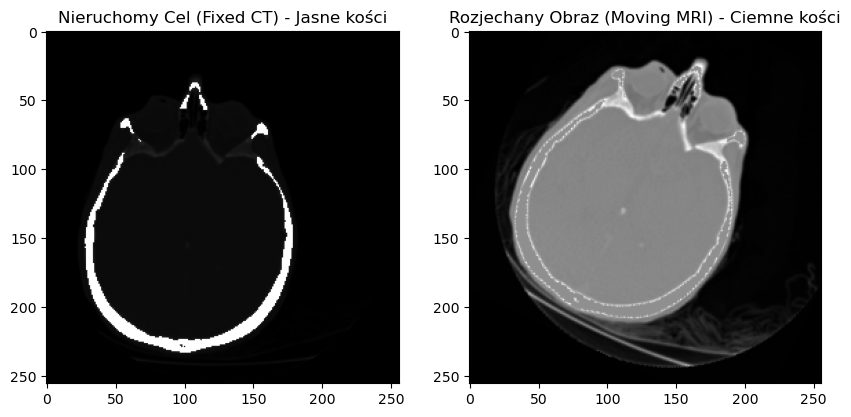

In [8]:
# Generowanie syntetycznego MRI
ct_arr = sitk.GetArrayFromImage(fixed_ct)
mri_arr = ct_arr.copy()
bone_mask = ct_arr > 0.45
mri_arr[bone_mask] = 0.05  # Ciemna czaszka
mri_arr = np.power(mri_arr, 0.6)  # Jasne struktury tkanek miękkich

moving_mri_orig = sitk.GetImageFromArray(mri_arr)
moving_mri_orig.CopyInformation(fixed_ct)

# Celowe zepsucie pozycji MRI (Wielomodalne)
transform_true_mri = sitk.Euler2DTransform()
transform_true_mri.SetCenter(center_pt)
transform_true_mri.SetTranslation((-12.0, 18.0))
transform_true_mri.SetAngle(np.radians(-25))

moving_mri = sitk.Resample(moving_mri_orig, fixed_ct, transform_true_mri, sitk.sitkLinear, 0.0, moving_mri_orig.GetPixelID())

fig, ax = plt.subplots(1, 2, figsize=(10,5))
ax[0].imshow(sitk.GetArrayFromImage(fixed_ct), cmap='gray'); ax[0].set_title("Nieruchomy Cel (Fixed CT) - Jasne kości")
ax[1].imshow(sitk.GetArrayFromImage(moving_mri), cmap='gray'); ax[1].set_title("Rozjechany Obraz (Moving MRI) - Ciemne kości")
plt.show()

In [10]:
# ---------------------------------------------------------
# MIEJSCE NA TWÓJ KOD (Zadanie 2 - Potok Rejestracji TK/MRI)
# ---------------------------------------------------------
R_mi = sitk.ImageRegistrationMethod()

# TODO 1: Ustaw metrykę na Informację Wzajemną Mattesa (Mattes Mutual Information)
# Ustaw liczbę koszyków histogramu (np. 50)
# ...

# TODO 2: Optymalizator i SKALOWANIE.
# Ustaw optymalizator (Gradient Descent), a następnie WŁĄCZ automatyczne skalowanie przesunięcia fizycznego!
# To uchroni algorytm przed przeskakiwaniem między kątami a milimetrami.
# ...
# R_mi.SetOptimizerScalesFromPhysicalShift()

# TODO 3: Włącz piramidę wielorozdzielczą (Multi-resolution Pyramid)!
# Ustaw ShrinkFactors (np. [4, 2, 1]) i SmoothingSigmas (np. [2, 1, 0])
# ...

# TODO 4: Zainicjalizuj transformację z MOMENTS i uruchom optymalizację
# ...

# Poniższy kod wygeneruje Kompozycję Kolorową RGB (TK=Czerwony, MRI=Zielony) do oceny wyniku:
try:
    registered_mri = sitk.Resample(moving_mri, fixed_ct, final_transform_mri, sitk.sitkLinear, 0.0, moving_mri.GetPixelID())
    
    ct_arr_viz = sitk.GetArrayFromImage(fixed_ct)
    mri_arr_viz = sitk.GetArrayFromImage(registered_mri)
    rgb = np.zeros((ct_arr_viz.shape[0], ct_arr_viz.shape[1], 3))
    rgb[..., 0] = ct_arr_viz
    rgb[..., 1] = mri_arr_viz
    
    plt.figure(figsize=(8, 8))
    plt.imshow(rgb)
    plt.title("Ocena dopasowania: Nakładka RGB\n(Czerwona kość powinna idealnie otaczać zielony mózg)")
    plt.show()
except NameError:
    print("Zmienna final_transform_mri nie została poprawnie zapisana!")

Zmienna final_transform_mri nie została poprawnie zapisana!
